In [1]:
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm as tq

In [2]:
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [3]:
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Rescaling
from tensorflow.keras.layers import RandomRotation, RandomTranslation, RandomZoom, RandomFlip
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau

In [4]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [5]:
# Setingan Manual Model
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 123
RANDOM_STATE = 42

In [6]:
from google.colab import files
files.view("/content/drive/MyDrive/DEEP_LEARNING/kaggle.json")

<IPython.core.display.Javascript object>

In [7]:
!kaggle datasets download -d ndisan/corn-leaf-disease
!unzip corn-leaf-disease.zip

Dataset URL: https://www.kaggle.com/datasets/ndisan/corn-leaf-disease
License(s): MIT
100% 5.11G/5.11G [02:32<00:00, 36.1MB/s]

Archive:  corn-leaf-disease.zip
  inflating: Bercak Daun/Corn_Gray_Spot (1).jpg  
  inflating: Bercak Daun/Corn_Gray_Spot (10).jpg  
  inflating: Bercak Daun/Corn_Gray_Spot (100).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (101).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (102).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (103).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (104).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (105).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (106).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (107).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (108).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (109).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (11).jpg  
  inflating: Bercak Daun/Corn_Gray_Spot (110).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (111).JPG  
  inflating: Bercak Daun/Corn_Gray_Spot (112).JPG  
  inflating:

In [8]:
if not os.path.exists("corn_leaf_disease"):
  os.makedirs("corn_leaf_disease")

if os.path.exists("Bercak Daun") or len(os.listdir("Bercak Daun")) > 0 :
  shutil.move("Bercak Daun", "corn_leaf_disease/Bercak Daun")
if os.path.exists("Hawar Daun") or len(os.listdir("Hawar Daun")) > 0 :
  shutil.move("Hawar Daun", "corn_leaf_disease/Hawar Daun")
if os.path.exists("Karat Daun") or len(os.listdir("Karat Daun")) > 0 :
  shutil.move("Karat Daun", "corn_leaf_disease/Karat Daun")
if os.path.exists("Daun Sehat") or len(os.listdir("Daun Sehat")) > 0 :
  shutil.move("Daun Sehat", "corn_leaf_disease/Daun Sehat")

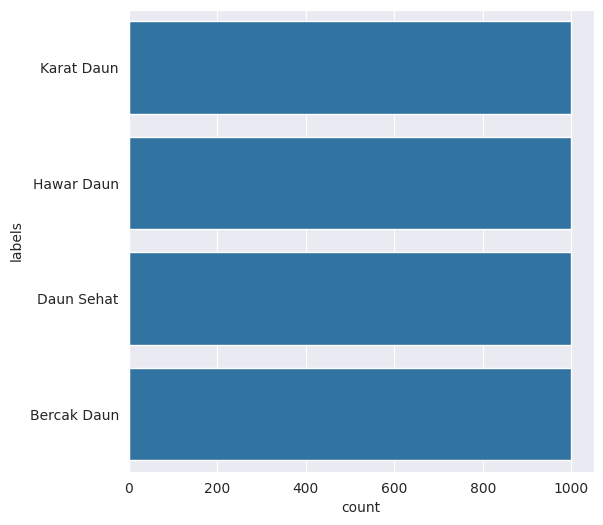

In [9]:
lung_path = "corn_leaf_disease"

file_name = []
labels = []
full_path = []

for path, subdirs, files in os.walk(lung_path):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

distribution_image = pd.DataFrame({"path":full_path, 'file_name':file_name, "labels":labels})

Label = distribution_image['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)

In [10]:
for distribusion in distribution_image['labels'].unique():
  print(f"Total {distribusion} : {distribution_image[distribution_image['labels'] == distribusion].count()['labels']}")

print("===================================================")
print(f"Total Dataset Image Keseluruhan : {Label.count()}")

Total Karat Daun : 1000
Total Hawar Daun : 1000
Total Daun Sehat : 1000
Total Bercak Daun : 1000
Total Dataset Image Keseluruhan : 4000


In [11]:
df = distribution_image.copy()
df.head()

,path,file_name,labels
0,corn_leaf_disease/Karat Daun/IMG_20230610_0712...,IMG_20230610_071214.jpg,Karat Daun
1,corn_leaf_disease/Karat Daun/IMG_20230610_0731...,IMG_20230610_073114.jpg,Karat Daun
2,corn_leaf_disease/Karat Daun/IMG_20230729_0645...,IMG_20230729_064527 (1).jpg,Karat Daun
3,corn_leaf_disease/Karat Daun/IMG_20230730_0609...,IMG_20230730_060929 (1).jpg,Karat Daun
4,corn_leaf_disease/Karat Daun/IMG_20230727_0605...,IMG_20230727_060513~2.jpg,Karat Daun


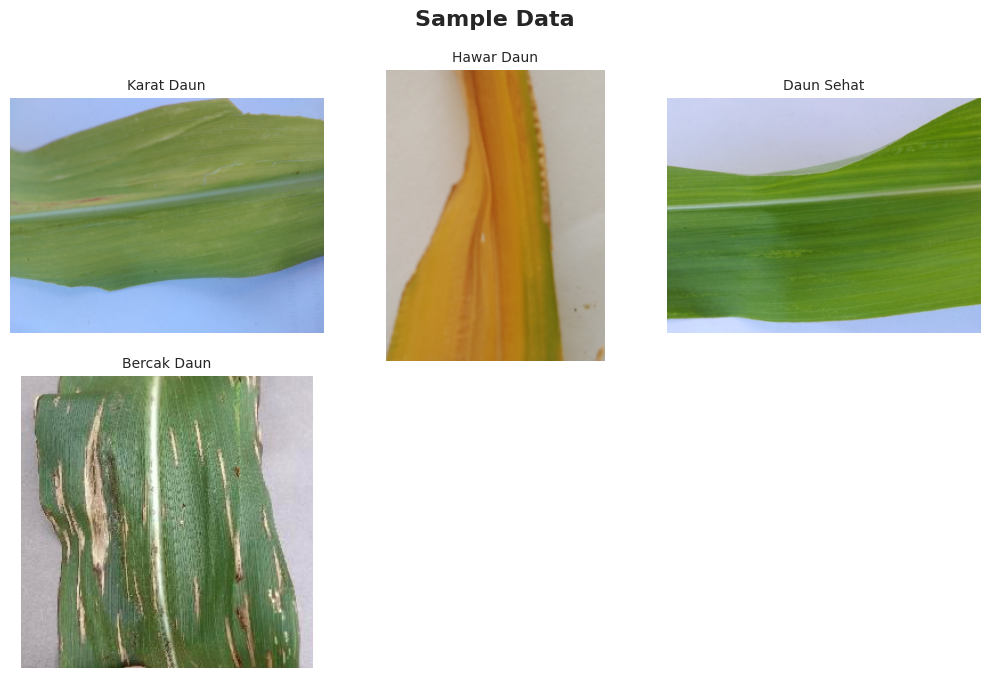

In [12]:
unique_labels = df['labels'].unique()

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
fig.suptitle("Sample Data", fontsize=16, fontweight='bold')

axes = axes.flatten()

# Looping untuk menampilkan gambar sesuai jumlah unique_labels
for i, uniq in enumerate(unique_labels):
    sample_path = df[df['labels'] == uniq]['path'].values[0]

    img = Image.open(sample_path)

    axes[i].imshow(img)
    axes[i].set_title(uniq, fontsize=10)
    axes[i].axis('off')

# Menyembunyikan sisa subplot yang kosong
for j in range(len(unique_labels), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

In [13]:
X= df['path']
y= df['labels']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=True, stratify=y)

In [14]:
df_tr = pd.DataFrame({'path':X_train,'labels':y_train,'set':'train'})
df_te = pd.DataFrame({'path':X_test,'labels':y_test,'set':'test'})
df_all = pd.concat([df_tr, df_te], ignore_index=True)

print('===================================================== \n')
print(df_all.groupby(['set', 'labels']).size(), '\n')
print('===================================================== \n')

print(df_all.sample(5))


set    labels     
test   Bercak Daun    200
       Daun Sehat     200
       Hawar Daun     200
       Karat Daun     200
train  Bercak Daun    800
       Daun Sehat     800
       Hawar Daun     800
       Karat Daun     800
dtype: int64 


                                                   path       labels    set
2759  corn_leaf_disease/Daun Sehat/IMG_20230610_0723...   Daun Sehat  train
3514  corn_leaf_disease/Daun Sehat/IMG_20230718_1722...   Daun Sehat   test
3737  corn_leaf_disease/Karat Daun/IMG_20230727_0637...   Karat Daun   test
3930  corn_leaf_disease/Bercak Daun/Corn_Gray_Spot (...  Bercak Daun   test
1782  corn_leaf_disease/Hawar Daun/IMG_20230727_0631...   Hawar Daun  train


In [15]:
df_all.head()

,path,labels,set
0,corn_leaf_disease/Karat Daun/IMG_20230718_0725...,Karat Daun,train
1,corn_leaf_disease/Hawar Daun/IMG_20230720_0630...,Hawar Daun,train
2,corn_leaf_disease/Hawar Daun/IMG_20230728_1658...,Hawar Daun,train
3,corn_leaf_disease/Bercak Daun/Corn_Gray_Spot (...,Bercak Daun,train
4,corn_leaf_disease/Daun Sehat/IMG_20230728_1546...,Daun Sehat,train


In [16]:
datasource_path = lung_path
dataset_path = "new_dataset/"

for index, row in tq(df_all.iterrows()):
    file_path = row['path']
    if os.path.exists(file_path) == False:
            file_path = os.path.join(datasource_path,row['labels'],row['image'].split('.')[0])

    if os.path.exists(os.path.join(dataset_path,row['set'],row['labels'])) == False:
        os.makedirs(os.path.join(dataset_path,row['set'],row['labels']))

    destination_file_name = file_path.split('/')[-1]
    file_dest = os.path.join(dataset_path,row['set'],row['labels'],destination_file_name)

    if os.path.exists(file_dest) == False:
        shutil.copy2(file_path,file_dest)

0it [00:00, ?it/s]

In [17]:
TRAIN_DIR = "new_dataset/train/"
TEST_DIR = "new_dataset/test/"
arr_train = []
arr_test = []

for key, data in enumerate(os.listdir(TRAIN_DIR)):
  dict_train = {"train_name" : f"train_{data}",
                "train_path" : os.path.join(f"{TRAIN_DIR}{data}")}
  arr_train.append(dict_train)
for key, data in enumerate(os.listdir(TEST_DIR)):
  dict_test = {"test_name" : f"test_{data}",
                "test_path" : os.path.join(f"{TEST_DIR}{data}")}
  arr_test.append(dict_test)

for ar_tr in arr_train:
  print(f"Total number of {ar_tr["train_name"].replace("_", " ")} : {len(os.listdir(ar_tr["train_path"]))}")

print("===================================================")

for ar_ts in arr_test:
  print(f"Total number of {ar_ts["test_name"].replace("_", " ")} : {len(os.listdir(ar_ts["test_path"]))}")

Total number of train Karat Daun : 800
Total number of train Hawar Daun : 800
Total number of train Daun Sehat : 800
Total number of train Bercak Daun : 800
Total number of test Karat Daun : 200
Total number of test Hawar Daun : 200
Total number of test Daun Sehat : 200
Total number of test Bercak Daun : 200


In [18]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False
)
class_names = test_dataset.class_names
NUM_CLASSES = len(train_dataset.class_names)
print(f"Jumlah kelas terdeteksi: {NUM_CLASSES}")

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Found 3200 files belonging to 4 classes.
Using 2560 files for training.
Found 3200 files belonging to 4 classes.
Using 640 files for validation.
Found 800 files belonging to 4 classes.
Jumlah kelas terdeteksi: 4


In [19]:
data_augmentation = Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2),
    RandomTranslation(height_factor=0.2, width_factor=0.2),
    RandomZoom(0.2),
], name="augmentation_layer")

# LAYER BARU KHUSUS MOBILENETV2 (Rumus: (x / 127.5) - 1 )
# Ini mengubah rentang 0-255 menjadi -1 sampai 1
mobilenet_preprocess = Rescaling(scale=1./127.5, offset=-1, name="mobilenet_rescale")

# Muat Base Model MobileNetV2
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# Rangkai Model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = mobilenet_preprocess(x)         # <--- Masukkan layer rescale di sini!
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_layer (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_rescale (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
# 1. Buat Custom Callback
class StopAtThreshold(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        # Mengecek apakah akurasi validasi sudah 96% (0.96) atau lebih
        if logs.get('val_accuracy') >= 0.96:
            print("\nTarget akurasi validasi 96% tercapai! Menghentikan training...")
            self.model.stop_training = True

# 2. Inisialisasi Custom Callback
stop_threshold = StopAtThreshold()

# 3. Gabungkan ke dalam callbacks_list
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(filepath='model_padi_mobilenetv2.keras', monitor='val_accuracy', save_best_only=True),
    stop_threshold  # <--- Custom callback ditambahkan di sini
]

In [21]:
print("\n--- MULAI TAHAP 1: FEATURE EXTRACTION ---")
history_1 = model.fit(train_dataset, validation_data=val_dataset, epochs=15, callbacks=callbacks_list)


--- MULAI TAHAP 1: FEATURE EXTRACTION ---
Epoch 1/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 143s 403ms/step - accuracy: 0.6996 - loss: 0.7583 - val_accuracy: 0.8328 - val_loss: 0.4126 - learning_rate: 0.0010
Epoch 2/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - accuracy: 0.8832 - loss: 0.3395 - val_accuracy: 0.9016 - val_loss: 0.2977 - learning_rate: 0.0010
Epoch 3/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.8961 - loss: 0.2875 - val_accuracy: 0.9047 - val_loss: 0.2633 - learning_rate: 0.0010
Epoch 4/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.9078 - loss: 0.2412 - val_accuracy: 0.9250 - val_loss: 0.2358 - learning_rate: 0.0010
Epoch 5/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.9168 - loss: 0.2392 - val_accuracy: 0.9281 - val_loss: 0.2121 - learning_rate: 0.0010
Epoch 6/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.9371 - loss: 0.2007 - val_accuracy: 0.9281 - val_loss: 0.2012 - learning_rate: 0.0010
Epoch 7/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/st

In [22]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
25/25 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.9488 - loss: 0.1644
--------------------------------------------------
TEST ACCURACY: 0.9488 (94.88%)
TEST LOSS:     0.1644
--------------------------------------------------


In [23]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

 Bercak Daun       0.99      0.99      0.99       200
  Daun Sehat       0.98      0.97      0.97       200
  Hawar Daun       0.92      0.93      0.92       200
  Karat Daun       0.90      0.91      0.91       200

    accuracy                           0.95       800
   macro avg       0.95      0.95      0.95       800
weighted avg       0.95      0.95      0.95       800



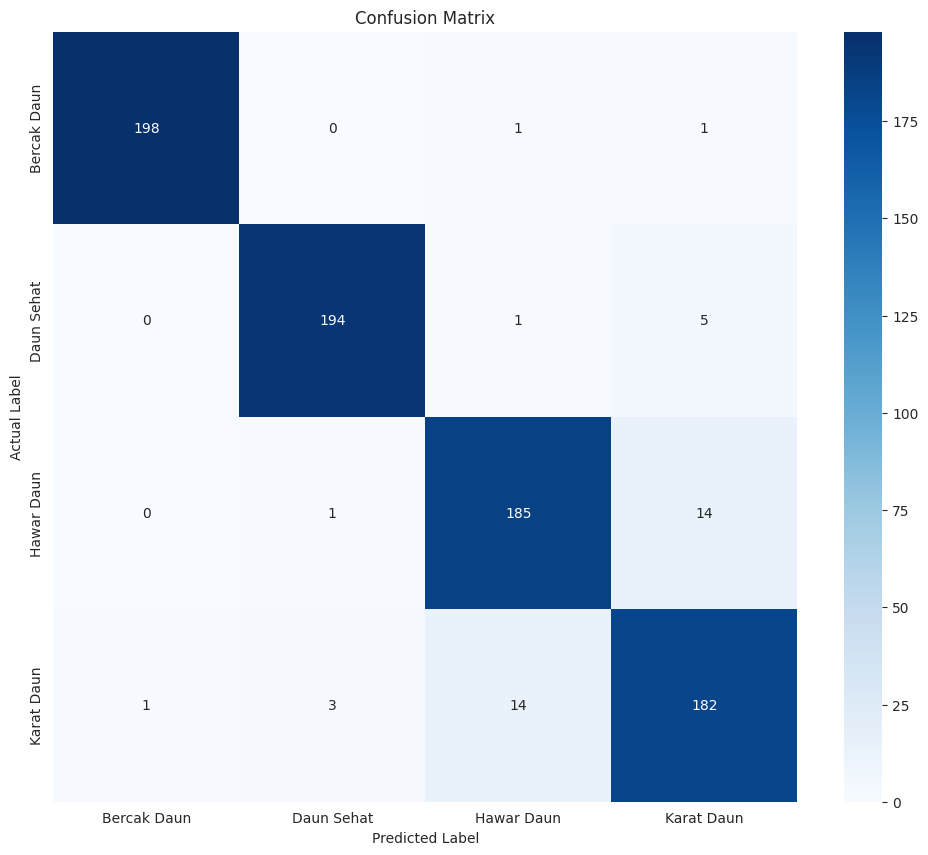

In [24]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

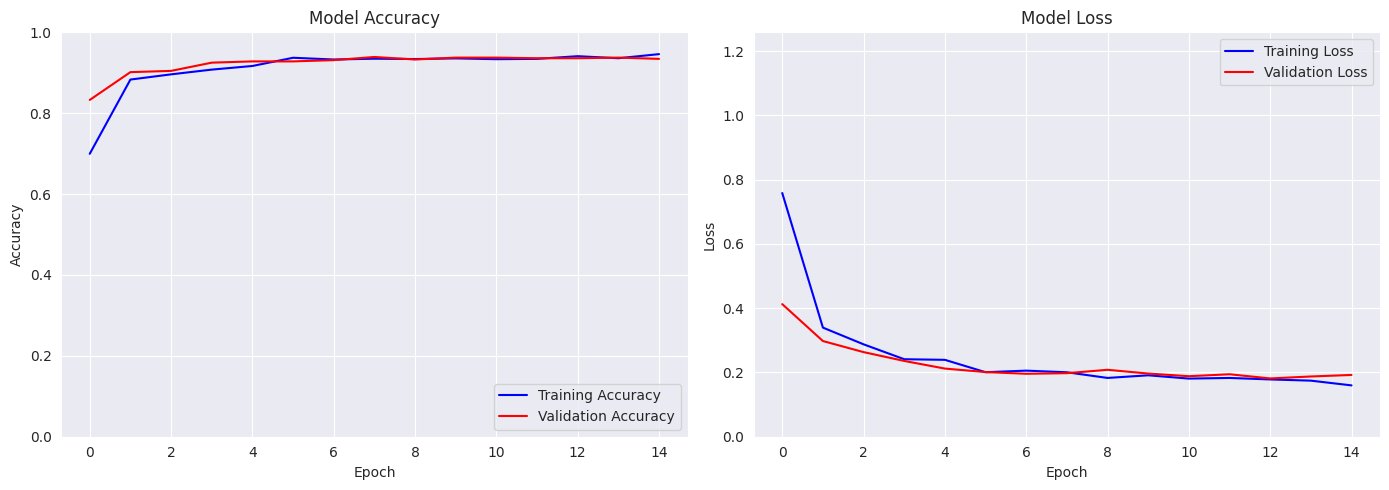

In [25]:
if 'history_1' in locals():
    acc = history_1.history['accuracy']
    val_acc = history_1.history['val_accuracy']
    loss = history_1.history['loss']
    val_loss = history_1.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [26]:
shutil.copy("/content/model_padi_mobilenetv2.keras", "/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/Corn_MobileNetV2_pre-trained.keras")

'/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/Corn_MobileNetV2_pre-trained.keras'

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


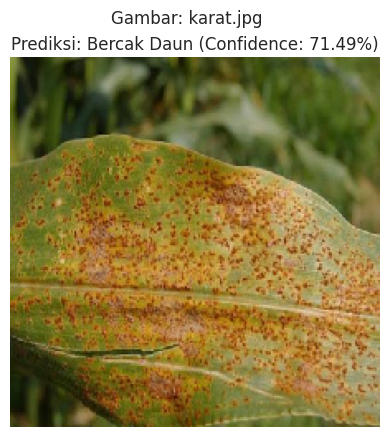

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


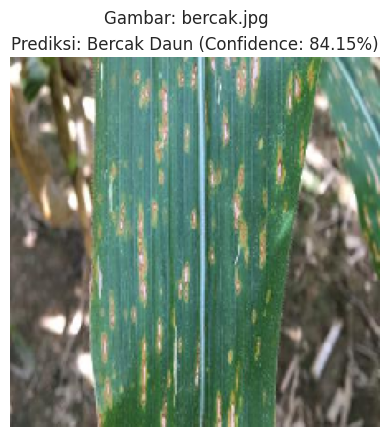

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


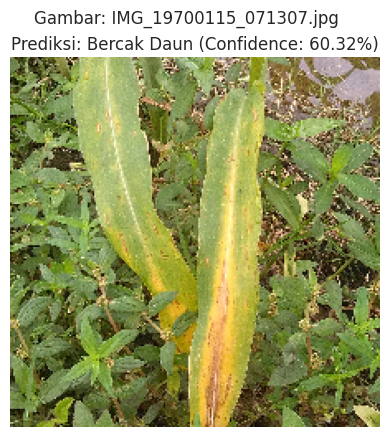

In [28]:
def predict_image(img_path, model, class_names):
    # 1. Muat gambar dan pastikan ukurannya sesuai dengan input model
    img = image.load_img(img_path, target_size=(224, 224))
    img_filename = os.path.basename(img_path)

    # 2. Ubah gambar menjadi array
    img_array = image.img_to_array(img)

    # 3. Tambahkan dimensi batch (dari (224, 224, 3) menjadi (1, 224, 224, 3))
    img_array = np.expand_dims(img_array, axis=0)

    # CATATAN: Rescale (img_array /= 255.0) sengaja ditiadakan untuk EfficientNet

    # 4. Lakukan prediksi
    predictions = model.predict(img_array)

    # 5. Ekstrak hasil
    predicted_class = np.argmax(predictions[0])
    confidence = np.max(predictions[0])

    # print(f'Predicted: {class_names[predicted_class]} (Confidence: {confidence:.2%})')
    plt.imshow(img)
    plt.title(f"Prediksi: {class_names[predicted_class]} (Confidence: {confidence:.2%})")
    plt.suptitle(f"Gambar: {img_filename}")
    plt.axis("off")
    plt.show()

    # Opsional: Kembalikan nilai jika ingin digunakan di variabel lain
    return class_names[predicted_class], confidence

for i in os.listdir("/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Sample"):
  predict_image(f"/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Sample/{i}", model, class_names)

In [29]:
print("\n--- MULAI TAHAP 2: FINE TUNING ---")
base_model.trainable = True

# Biarkan Batch Normalization membeku
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # LR SANGAT KECIL
              loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()


--- MULAI TAHAP 2: FINE TUNING ---


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_layer (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_rescale (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 2,194,884 (8.37 MB)

 Non-trainable params: 68,224 (266.50 KB)

In [30]:
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(filepath='model_padi_mobilenetv2.keras', monitor='val_accuracy', save_best_only=True),
]

In [31]:
history_2 = model.fit(train_dataset, validation_data=val_dataset, epochs=20, callbacks=callbacks_list)

Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 25s 172ms/step - accuracy: 0.9352 - loss: 0.1702 - val_accuracy: 0.9531 - val_loss: 0.1571 - learning_rate: 1.0000e-05
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 152ms/step - accuracy: 0.9473 - loss: 0.1488 - val_accuracy: 0.9594 - val_loss: 0.1507 - learning_rate: 1.0000e-05
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 147ms/step - accuracy: 0.9445 - loss: 0.1565 - val_accuracy: 0.9516 - val_loss: 0.1430 - learning_rate: 1.0000e-05
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 147ms/step - accuracy: 0.9508 - loss: 0.1257 - val_accuracy: 0.9500 - val_loss: 0.1528 - learning_rate: 1.0000e-05
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 14s 173ms/step - accuracy: 0.9570 - loss: 0.1283 - val_accuracy: 0.9547 - val_loss: 0.1295 - learning_rate: 1.0000e-05
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 149ms/step - accuracy: 0.9570 - loss: 0.1192 - val_accuracy: 0.9578 - val_loss: 0.1251 - learning_rate: 1.0000e-05
Epoch 7/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 150ms/step - acc

In [32]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.9625 - loss: 0.1165
--------------------------------------------------
TEST ACCURACY: 0.9625 (96.25%)
TEST LOSS:     0.1165
--------------------------------------------------


In [33]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

 Bercak Daun       1.00      1.00      1.00       200
  Daun Sehat       0.98      0.98      0.98       200
  Hawar Daun       0.93      0.95      0.94       200
  Karat Daun       0.93      0.92      0.92       200

    accuracy                           0.96       800
   macro avg       0.96      0.96      0.96       800
weighted avg       0.96      0.96      0.96       800



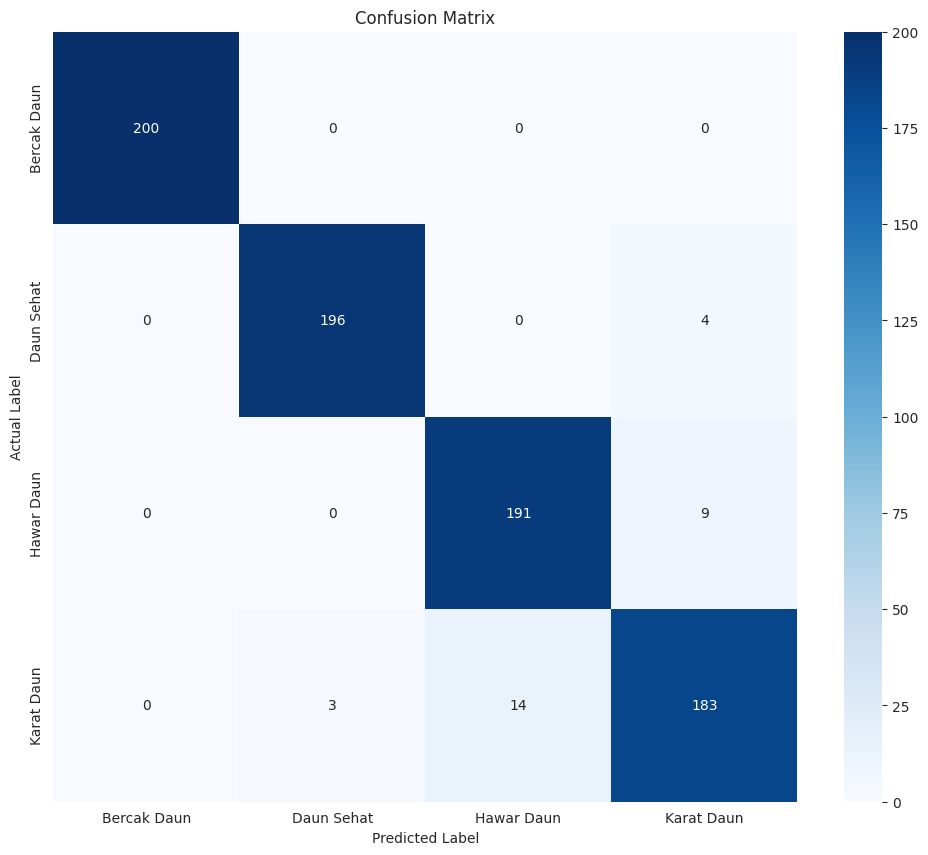

In [34]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

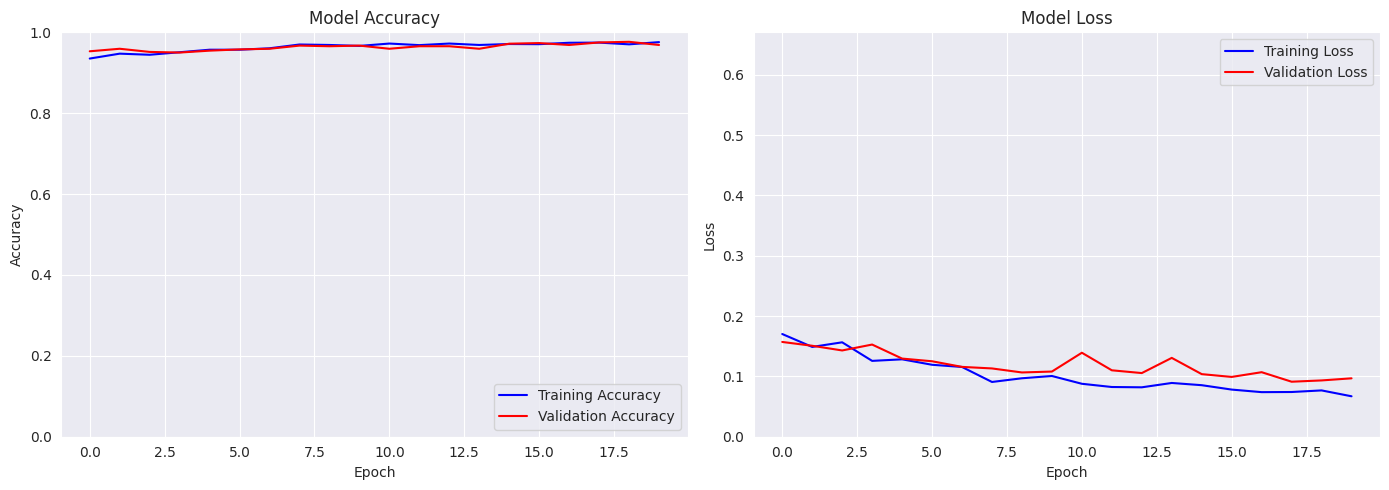

In [35]:
if 'history_2' in locals():
    acc = history_2.history['accuracy']
    val_acc = history_2.history['val_accuracy']
    loss = history_2.history['loss']
    val_loss = history_2.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [36]:
shutil.copy("/content/model_padi_mobilenetv2.keras", "/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/Corn_MobileNetV2_fine-tuning.keras")

'/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/Corn_MobileNetV2_fine-tuning.keras'

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


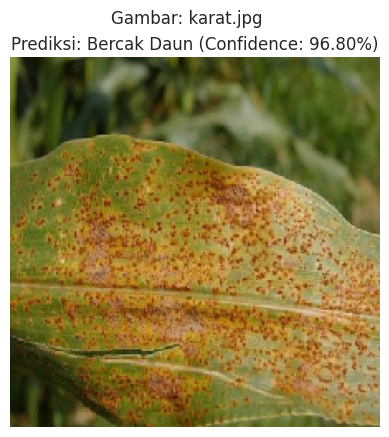

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


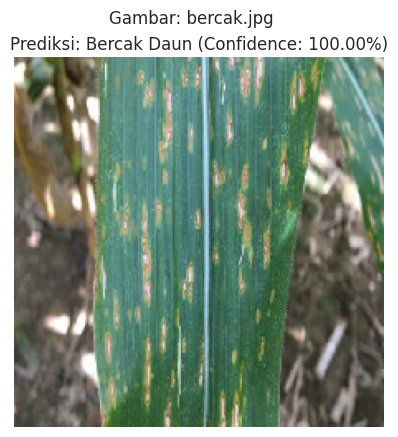

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


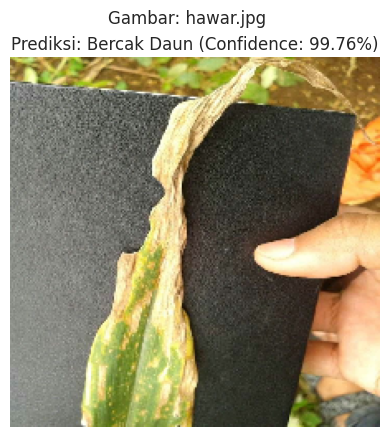

In [39]:
for i in os.listdir("/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Sample"):
  predict_image(f"/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Sample/{i}", model, class_names)

In [40]:
model = tf.keras.models.load_model('/content/model_padi_mobilenetv2.keras')
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT] # Optimasi ukuran
tflite_model = converter.convert()

with open('/content/drive/MyDrive/DEEP_LEARNING/Corn Disease/Model/Corn_MobileNetV2_fine-tuning.tflite', 'wb') as f:
    f.write(tflite_model)

Saved artifact at '/tmp/tmpuax78mq8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  137685085717712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137687402432464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137687402433424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137685085716944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137687402440528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137687402437264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137687402445712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137687402445136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137687402435920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137687402446096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1376874024351